# Binaryzacja

### Zadanie domowe - binaryzacja adaptacyjna w oknach z interpolacją.

Pokazana w ramach podstawowej części ćwiczenia binaryzacja adaptacyjna daje dobre rezultaty (zwłaszcza metoda Sauvoli), ale jest dość złożona obliczeniowo (choć oczywiście należy mieć świadomość, że implementację można zoptymalizować i wyeliminować pewne powtarzające się obliczenia).
Zbliżone rozwiązanie można również realizować w nieco innym wariancie - w oknach.
Ogólna idea jest następująca: wejściowy obraz dzielimy na nienachodzące (rozłączne) okna - wygodnie jest założyć, że są one kwadratowe i o rozmiarze będącym potęgą liczby 2.
W każdym z okien obliczamy próg - niech to będzie średnia i stosujemy do binaryzacji lokalnej.
Jak nietrudno się domyślić efekt nie będzie dobry, gdyż na granicach okien wystąpią artefakty.
Aby je wyeliminować należy zastosować interpolację, co zostanie szczegółowo opisane poniżej.
Warto zaznaczyć, że podobny mechanizm interpolacji stosowany jest w poznanym wcześniej algorytmie CLAHE.

Do wykonania ostatniego punktu potrzebne będą implementacje z ćwiczenia podstawowego (Otsu, binaryzacja lokalna na podstawie średniej i metoda Sauvoli).


Na początek zaimplementujemy wariant metody bez interpolacji:
1. Wczytaj obraz _rice.png_ w odcieniach szarości (rozmiar $256 \times 256$).
2. W dwóch pętlach `for`, dla okien o ustalonym wymiarze $W$ (potęga 2, np. 16 lub 32 - wtedy $W$ dzieli rozmiar obrazu), oblicz średnią:
- pętle powinny mieć krok $W$,
- wynik (tj. średnie) należy zapisać w pomocniczej tablicy,
- przydatny operator to `//` - dzielenie całkowitoliczbowe (*floor division*).

3. W kolejnych dwóch pętlach `for` (tym razem o kroku 1) przeprowadź binaryzację z wyznaczonymi progami.
   Tu oczywiście należy się sprytnie odwołać do wyników z tablicy pomocniczej.
   Wyświetl wyniki - czy jest on poprawny?
   Podpowiedź - błędy lepiej widać dla mniejszego rozmiaru okna (np. 16 x 16).

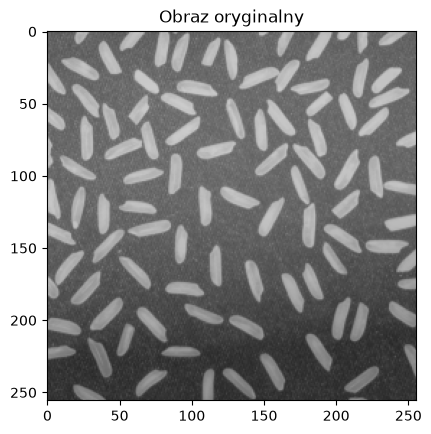

In [1]:
import cv2
import requests
from pathlib import Path
from matplotlib import pyplot as plt
import numpy as np

katalog = Path('.')
url = 'https://raw.githubusercontent.com/vision-agh/poc_sw/master/04_Thresholding/'
for nazwa in ['rice.png', 'catalogue.png']:
    plik = katalog / nazwa
    if not plik.exists():
        r = requests.get(url + nazwa, timeout=30)
        r.raise_for_status()
        plik.write_bytes(r.content)

rice = cv2.imread(str(katalog / 'rice.png'), cv2.IMREAD_GRAYSCALE)
plt.imshow(rice, cmap='gray', vmin=0, vmax=255)
plt.title('Obraz oryginalny')
plt.show()

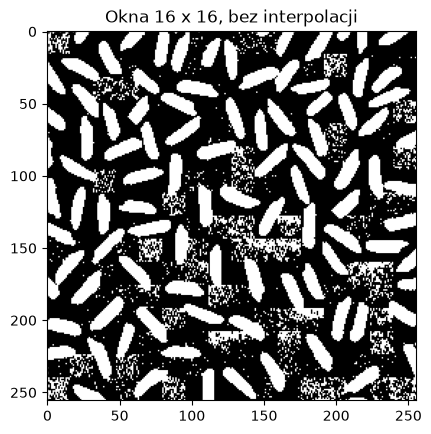

In [2]:
def progi_okien(obraz, W):
    Y, X = obraz.shape
    progi = np.zeros((Y // W, X // W))
    for j in range(0, Y, W):
        for i in range(0, X, W):
            progi[j // W, i // W] = obraz[j:j+W, i:i+W].mean()
    return progi


def bez_interpolacji(obraz, progi, W):
    Y, X = obraz.shape
    wynik = np.zeros_like(obraz)
    for j in range(Y):
        for i in range(X):
            wynik[j, i] = obraz[j, i] > progi[j // W, i // W]
    return wynik

W = 16  # rozmiar obrazu 256 x 256 jest podzielny przez W
progi = progi_okien(rice, W)
wynik_bez = bez_interpolacji(rice, progi, W)
plt.imshow(wynik_bez, cmap='gray', vmin=0, vmax=1)
plt.title(f'Okna {W} x {W}, bez interpolacji')
plt.show()

In [ ]:
# widac prostokatne skoki

4. Rozwiązaniem problemu artefaktów na obrazie jest zastosowanie interpolacji.
   Próg binaryzacji dla danego piksela wyliczany jest na podstawie progów z sąsiednich okien.
   ![Ilustracja koncepcji interpolacji](https://raw.githubusercontent.com/vision-agh/poc_sw/master/04_Thresholding/clahe_tile_interpolation.png)

   Koncepcja została przedstawiona na powyższym rysunku.
   Możliwe są 3 przypadki:
   - piksel leży w rogach obrazu (kolor czerwony) - wtedy za próg przyjmuje się wartość średniej obliczonej dla danego okna,
   - piksel leży na krawędzi obrazu (kolor zielony) - wtedy za próg przyjmuje się wartość obliczoną na podstawie średnich z dwóch sąsiednich okien,
   - piksel leży w środku (kolor fioletowy) - wtedy próg jest obliczany na podstawie 4 sąsiednich okien.

   Uwaga. Proszę zwrócić uwagę, że sprawa jest dość złożona.
   Obraz dzielimy na okna (dla nich liczymy średnią) i następnie każde z okien "wirtualnie" na cztery sub-okna (linie przerywane).
   To ułatwia znalezienie środków okien (czarne kwadraty), które są wykorzystywane w interpolacji.

5. Implementujemy interpolację.
   Potrzebujemy do tego znać progi (jeden, dwa lub cztery), ale dla przejrzystości obliczeń lepiej zawsze przyjąć cztery oraz odległości od rozważanego piksela do środka sąsiednich okien (też w ogólnym przypadku 4):
   - całość sprowadza się do określania pozycji piksela,
   - na początek rozważmy przypadek czterech narożników (kolor czerwony na rysunku) - trzeba napisać `if`, który je wyznaczy,
   - warto sprawdzić, czy nie popełniliśmy błędu i np. tymczasowo do obrazu wynikowego w tym miejscu przypisać wartość 255. Efekt powinien być taki, że widoczne będą tylko narożniki.
   - drugi przypadek do brzegi (kolor zielony) - postępujemy podobnie jak przy narożnikach, przy czym osobno wydzielamy brzegi pionowe i poziome. Tu też warto sobie obrazek "pokolorować".
   - na koniec wyznaczamy piksele w środku.
   - analizując poprawność proszę zwrócić uwagę na to, żeby nie było przerw pomiędzy obszarami.
   - mając podział możemy dla każdego z obszarów wyliczyć cztery progi ($t11, t12, t21, t22$):
        - dla narożników wartość ta będzie identyczna i wynosi po prostu `t11 =t[jT][iT]`, gdzie `iT=i//W` oraz `jT=j//W`.
          Uwaga. Proszę używać indeksów tymczasowych $jT,iT$, gdyż będą potrzebne w dalszych obliczeniach.
        - dla brzegów pionowych występują dwie wartości: okno bieżące i sąsiednie.
          Wyznaczenie współrzędnej poziomej jest proste (jak dla narożników).
          Nad współrzędną pionową trzeba się chwilę zastanowić - aby nie rozważać wielu przypadków można od bieżącej współrzędnej odjąć połowę rozmiaru okna i dopiero później wykonać dzielenie przez rozmiar okna.
          W ten sposób otrzymujemy indeks okna o mniejszej współrzędnej.
          Indeks drugiego uzyskamy dodając 1.
          Proszę się zastanowić dlaczego to działa - najlepiej to sobie rozrysować.
          W osi poziomej oba okna są takie same (jak dla narożników), tzn. `t12 = t11` oraz `t22 = t21`.
        - dla brzegów poziomych należy postąpić analogicznie (tym razem `t21 = t11` oraz `t22 = t12`),
        - obliczenia dla obszaru wewnątrz powinny być już oczywiste.
        - w każdej gałęzi `if` należy przypisać wszystkie cztery wartości ($t11, t12, t21, t22$) - w przeciwnym razie zostaną w nich wartości z poprzednio przetwarzanego piksela!
   - kolejny krok to wyliczenie odległości pomiędzy rozważanym pikselem, a czterema środkami.
     Przykładowo dla osi X wygląda to następująco: `dX1 = i - W/2 - iT*W` oraz `dX2 = (iT+1)*W - (i - W/2)`.
     Dla osi Y analogicznie.
     Ponownie proszę się zastanowić dlaczego to jest poprawne - najlepiej to sobie narysować.
     W narożnikach i na brzegach tak wyznaczone wagi mogą wyjść poza przedział $[0, 1]$, ale nie ma to znaczenia, gdyż odpowiadające sobie progi są wtedy identyczne.
   - ostatni krok to interpolacja dwuliniowa.
     Wykonamy ją w trzech krokach:
     - interpolacja w osi X dla dwóch górnych okien - sprowadza się ona do średniej ważonej pomiędzy wartościami $t11$ i $t12$, przy czym wagi to odpowiednio $dX2/W$ i $dX1/W$.
       Ponownie na podstawie rysunku proszę to przemyśleć.
     - interpolacja w osi X dla dolnych okien jest analogiczna,
     - interpolacja w osi Y również jest analogiczna, z tym, że wejściem są dwa wyniki interpolacji w poziomie.

6. "Kropka nad i" to oczywiście binaryzacja z wyznaczonym poprzez interpolację progiem - proszę dobrać rozmiar okna.
7. Na koniec proszę porównać na wspólnym rysunku (dla obrazu _rice.png_, a dla chętnych także _catalogue.png_) poznane metody binaryzacji:
- Otsu,
- lokalna na podstawie średniej,
- lokalna Sauvoli,
- lokalna w oknach bez interpolacji,
- lokalna w oknach z interpolacją.

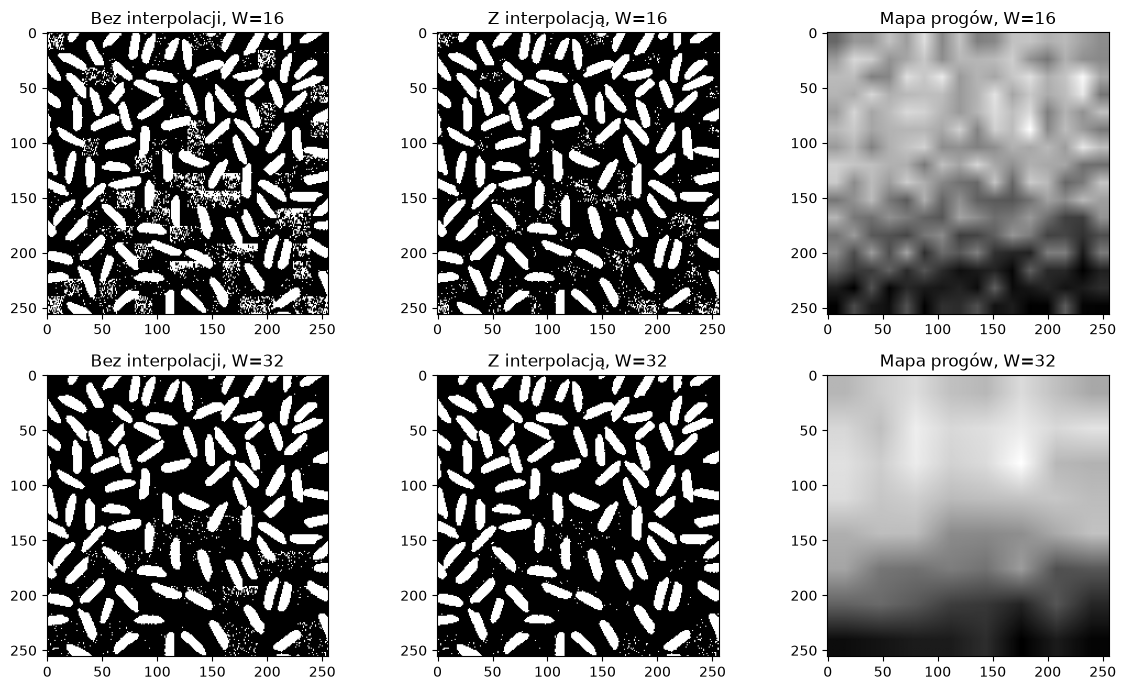

In [3]:
def z_interpolacja(obraz, progi, W):
    Y, X = obraz.shape
    mapa_progow = np.zeros((Y, X))
    for j in range(Y):
        for i in range(X):
            brzeg_x = i < W // 2 or i >= X - W // 2
            brzeg_y = j < W // 2 or j >= Y - W // 2

            if brzeg_x and brzeg_y:  # narożniki: jedno okno
                jT, iT = j // W, i // W
                t11 = t12 = t21 = t22 = progi[jT, iT]
            elif brzeg_x:  # brzeg pionowy: dwa okna nad sobą
                jT, iT = (j - W // 2) // W, i // W
                t11 = t12 = progi[jT, iT]
                t21 = t22 = progi[jT + 1, iT]
            elif brzeg_y:  # brzeg poziomy: dwa okna obok siebie
                jT, iT = j // W, (i - W // 2) // W
                t11 = t21 = progi[jT, iT]
                t12 = t22 = progi[jT, iT + 1]
            else:  # wnętrze: cztery sąsiednie okna
                jT = (j - W // 2) // W
                iT = (i - W // 2) // W
                t11 = progi[jT, iT]
                t12 = progi[jT, iT + 1]
                t21 = progi[jT + 1, iT]
                t22 = progi[jT + 1, iT + 1]

            dX1 = i - W / 2 - iT * W
            dX2 = W - dX1
            dY1 = j - W / 2 - jT * W
            dY2 = W - dY1

            gora = t11 * dX2 / W + t12 * dX1 / W
            dol = t21 * dX2 / W + t22 * dX1 / W
            mapa_progow[j, i] = gora * dY2 / W + dol * dY1 / W

    wynik = (obraz > mapa_progow).astype(np.uint8)
    return wynik, mapa_progow

plt.figure(figsize=(12, 7))
for wiersz, W in enumerate([16, 32]):
    progi = progi_okien(rice, W)
    wynik_bez = bez_interpolacji(rice, progi, W)
    wynik_z, mapa = z_interpolacja(rice, progi, W)
    for kolumna, (tytul, obraz) in enumerate([
        ('Bez interpolacji', wynik_bez),
        ('Z interpolacją', wynik_z),
        ('Mapa progów', mapa)
    ]):
        plt.subplot(2, 3, wiersz * 3 + kolumna + 1)
        plt.imshow(obraz, cmap='gray')
        plt.title(f'{tytul}, W={W}')
plt.tight_layout()
plt.show()

### porownanie

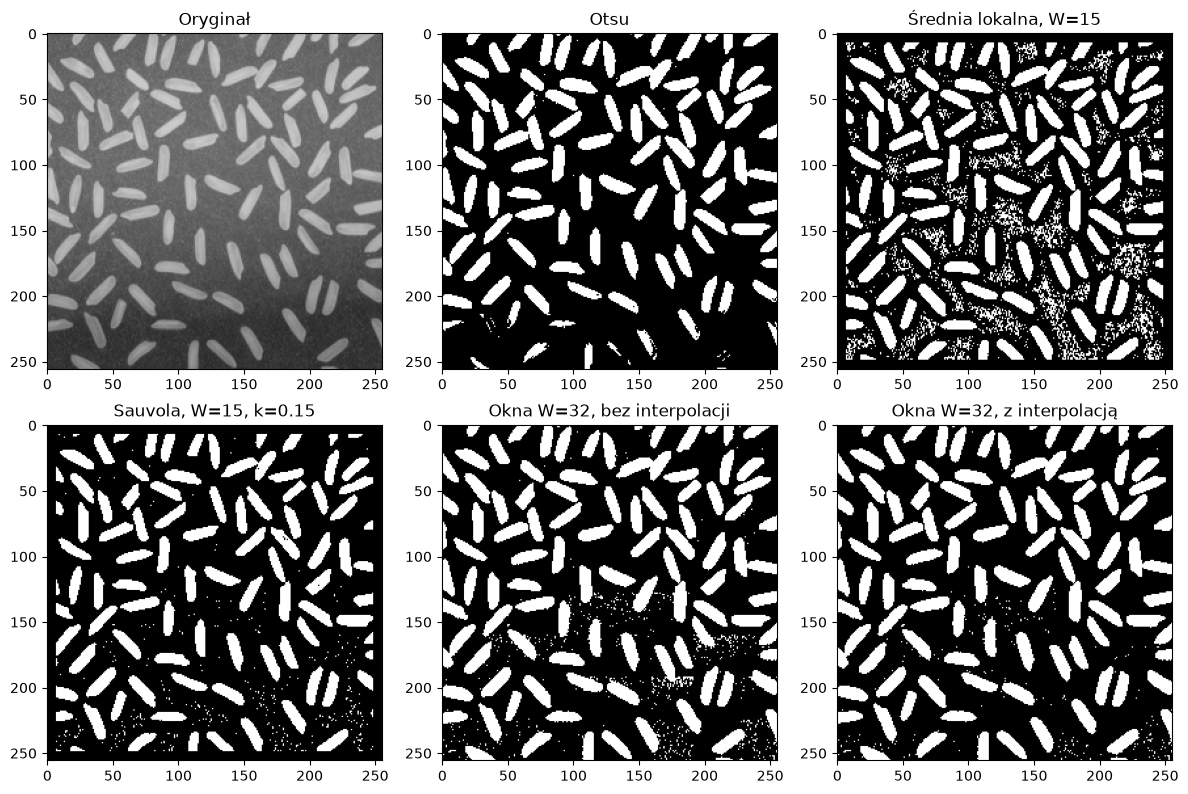

In [4]:
def prog_otsu(obraz):
    histogram, _ = np.histogram(obraz, bins=256, range=(0, 256))
    p = histogram / obraz.size
    mG = np.dot(np.arange(256), p)
    wariancja = np.zeros(256)
    P0 = 0.0
    m = 0.0
    for k in range(256):
        P0 += p[k]
        m += k * p[k]
        if 0 < P0 < 1:
            wariancja[k] = (mG * P0 - m)**2 / (P0 * (1 - P0))
    return int(np.argmax(wariancja)), wariancja

def binaryzacja_lokalna(obraz, W=15):
    Y, X = obraz.shape
    r = W // 2
    wynik = np.zeros_like(obraz)
    for j in range(r, Y - r):
        for i in range(r, X - r):
            okno = obraz[j-r:j+r+1, i-r:i+r+1]
            wynik[j, i] = obraz[j, i] > okno.mean()
    return wynik

def sauvola(obraz, W=15, k=0.15, R=128, znak=1):
    Y, X = obraz.shape
    r = W // 2
    wynik = np.zeros_like(obraz)
    for j in range(r, Y - r):
        for i in range(r, X - r):
            okno = obraz[j-r:j+r+1, i-r:i+r+1]
            srednia = okno.mean()
            odchStd = okno.std()
            T = srednia * (1 + znak * k * (odchStd / R - 1))
            wynik[j, i] = obraz[j, i] > T
    return wynik

prog, _ = prog_otsu(rice)
W = 32
progi = progi_okien(rice, W)
wynik_z, _ = z_interpolacja(rice, progi, W)
wyniki = [
    ('Oryginał', rice),
    ('Otsu', (rice > prog).astype(np.uint8)),
    ('Średnia lokalna, W=15', binaryzacja_lokalna(rice, W=15)),
    ('Sauvola, W=15, k=0.15', sauvola(rice, W=15, k=0.15, znak=-1)),
    ('Okna W=32, bez interpolacji', bez_interpolacji(rice, progi, W)),
    ('Okna W=32, z interpolacją', wynik_z)
]
plt.figure(figsize=(12, 8))
for i, (tytul, obraz) in enumerate(wyniki):
    plt.subplot(2, 3, i + 1)
    plt.imshow(obraz, cmap='gray', vmin=0, vmax=255 if i == 0 else 1)
    plt.title(tytul)
plt.tight_layout()
plt.show()

Wnioski: Otsu stosuje jeden próg, więc nie radzi sobie z nierównym oświetleniem.

Lokalna średnia lepiej dopasowuje próg, ale wzmacnia drobne wahania tła. 

Sauvola ze znakiem minus podnosi próg i lepiej oddziela jasny ryż od tła. 

Interpolacja usuwa skoki progów między oknami, lecz sama średnia nadal może powodować plamki